# Lab 9: Advanced Classification

This lab will give you a chance to practice and experiment with:
* Decision Trees
* Random Forests
* Cross Validation

Fun fact: it's the penultimate lab!


## Preliminaries

Note that this lab only has 3 questions, but they have more parts (so it's functionally like having 4 normal questions).  

* You should be able to do questions 1-2d by Monday 
* Make sure your code exactly conforms to specifications (e.g. exactly matching variable names)
* Make sure your code works with any provided test code, and do NOT modify that test code unless explicitly stated
* When answering a specific question, ensure that all your data is within the relevant block.  For text-based answers, you will be asked to edit a specific markdown cell.  For code-based answers, please make sure all code is wholly contained within the relevant  `BEGIN` and `END` comments.
* Please be sure to run the first cell (to import libraries) any time you work on your code.  Please be sure to run all cells, from start to finish, before you submit.  Make sure they run without error, that all provided tests pass, etc.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
from scipy import stats
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.naive_bayes import CategoricalNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import load_breast_cancer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import validation_curve

# Question 1: Understanding Decision Trees

In this question, we'll work towards understanding decision trees.  This (fake) data set shows information about the weather from 20 days, and indicates whether the person did an outdoor sport (say, skiing, frisbee, soccer, or kayaking) that day.  Let's load the data and visualize it

In [3]:
# Load the data


responses = ['Yes', 'Yes', 'No', 'Yes', 'Yes', 'No', 'Yes', 'Yes', 'No', 'Yes',
             'No',  'No',  'No', 'No',  'No',  'No', 'No',  'Yes', 'Yes', 'Yes']
temperatures = [18, 19, 22, 24, 26, 30, 57, 58, 60, 61,
                63, 64, 65, 67, 68, 70, 72, 73, 75, 77]
humidity = [0.4, 0.45, 0.2, 0.35, 0.59, 0.18, 0.35, 0.3, 0.85, 0.18,
             0.55,  0.74,  0.86, 0.75,  0.85,  0.8, 0.8,  0.15, 0.45, 0.4]


temp_df = pd.DataFrame({
    'Temperature': temperatures,
    'Humidity': humidity,
    'Sport': responses
})
temp_df.head(4)

,Temperature,Humidity,Sport
0,18,0.40,Yes
1,19,0.45,Yes
2,22,0.20,No
3,24,0.35,Yes


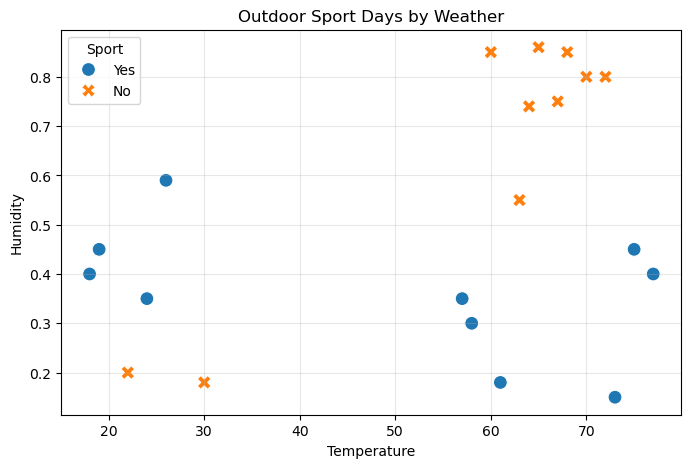

In [4]:
# Visualize it

plt.figure(figsize=(8, 5))
sns.scatterplot(data=temp_df, x='Temperature', y='Humidity', hue='Sport', style='Sport', s=100)
plt.title("Outdoor Sport Days by Weather")
plt.grid(True, alpha=0.3)
plt.show()

1a: Type a "Flow chart" describing how you might classify whether or not a day is a sports day by the temperature and humidity.  Use the following format (though this is not at all correct - just a template).  

* If the temperature is above 70 degrees:
  * If the humidity is above 42%:
    * classify "Yes"
  * Else:
    * classify "No"

Be sure to use indentations to signal nesting.  Double clicking on this cell to copy and paste a starter template.

* If the humidity is above 66.5%:
  * classify "No"
* Else:
  * If the humidity is below 25%:
    * If the temperature is below 45.5 degrees:
      * classify "No"
    * Else:
      * classify "Yes"
  * Else:
    * If the humidity is below 50%:
      * classify "Yes"
    * Else:
      * If the temperature is below 44.5 degrees:
        * classify "Yes"
      * Else:
        * classify "No"


1b: Let's restrict ourselves for now to just looking at one of our features: temperature.  Suppose we classified using the following:
* If temperature < 71: predict "No"
* If temperature >= 71: predict "Yes"

How many points would be misclassified?  What would the overall Gini error be?  Show your work.

Hint: Recall that to compute the Gini index in a given region, we let $\hat{p}_1$ be the proportion of observations from class 1 in that region, we let $\hat{p}_2$ be the proportion of observations from class 2 in that region, and we compute $\hat{p}_1(1-\hat{p}_1)+\hat{p}_2(1-\hat{p}_2)$.  Then to get the overall Gini error, we compute

(Fraction of data in class 1)(Gini index in region 1)+(Fraction of data in class 2)(Gini index in region 2)

For the split at 71 degrees:

* Left region (`Temperature < 71`): 16 points total
  * `Yes = 7`
  * `No = 9`
  * So this region is classified as `No`, and it misclassifies `7` points.

* Right region (`Temperature >= 71`): 4 points total
  * `Yes = 3`
  * `No = 1`
  * So this region is classified as `Yes`, and it misclassifies `1` point.

So the total number of misclassified points is:

`7 + 1 = 8`

Now compute the Gini index in each region.

For the left region: 

$\hat p_{Yes} = 7/16,\quad \hat p_{No} = 9/16$

$Gini_{left} = \frac{7}{16}\left(1-\frac{7}{16}\right) + \frac{9}{16}\left(1-\frac{9}{16}\right)
= \frac{126}{256} = 0.4921875$

For the right region:

$\hat p_{Yes} = 3/4,\quad \hat p_{No} = 1/4$


$Gini_{right} = \frac{3}{4}\left(1-\frac{3}{4}\right) + \frac{1}{4}\left(1-\frac{1}{4}\right)
= 0.375$

Weighted overall Gini error:

$\frac{16}{20}(0.4921875) + \frac{4}{20}(0.375)
= 0.39375 + 0.075
= 0.46875$

So the overall Gini error is `0.46875`.


1c: Let's write a function `best_temp_split_error` to find the split point for temperature that minimizes the number of misclassified points.  Specifically, this function should:
* Consider all 19 midpoints between succesive temperatures (e.g., based on our data, 18.5 [midpoint of 18 and 19], then 20.5 [midpoint of 19 and 22], etc).  
* For each midpoint, divide the data into two subsets: left (all the temperatures smaller than the midpoint) and right (all the temperatures bigger than it)
  * Assign all the data in each subset to its most popular class in that subset.  If you have a tie, default to class "No" for that entire subset
  * Compute the number of misclassified points in each subset and add them together.  This is the number of misclassified points for that temperature split point. (For instance, when you consider the temperature split point of 71 degrees, you should get whatever you found for the first part of 1b!).  Hint: if `labels` is a series storing the `Sport` labels for one of your subsets, the number of misclassified points in that subset is `len(labels)-labels.value_counts().max()`
* At the end, return two things: the best split point and the number of misclassified points with that split

You may write helper functions if you want, and you don't need comments/docstrings.

In [5]:
# BEGIN QUESTION 1c
def best_temp_split_error(df):
    temps = sorted(df["Temperature"].unique())
    mids = [(temps[i] + temps[i+1]) / 2 for i in range(len(temps)-1)]
    
    bestsplit = None
    minerror = float("inf")
    
    for mid in mids:
        left = df[df["Temperature"] < mid]["Sport"]
        right = df[df["Temperature"] > mid]["Sport"]
        
        left_error = len(left) - left.value_counts().max()
        right_error = len(right) - right.value_counts().max()
        total_error = left_error + right_error
        
        if total_error < minerror:
            minerror = total_error
            bestsplit = mid
            
    return bestsplit, minerror

    
# END QUESTION 1c

bestsplit, minerror = best_temp_split_error(temp_df)
print("Best split point: ", bestsplit)
print("Number Misclassified Points with This Split Point: ", minerror)
try:
    if 5 <= minerror <= 6:
        print("Public test for 1c passed")
    else:
        print("Public test for 1c FAILED")
except:
    print("Public test for 1c FAILED")


Best split point:  59.0
Number Misclassified Points with This Split Point:  6
Public test for 1c passed


1d: Now lets do the same but with the overall Gini error.  Specifically, write a function `best_temp_split_gini_error` to find the best split point for temperature in terms of the overall Gini error.  Specifically, this function should:
* Consider all 19 midpoints between succesive temperatures (e.g., 18.5, then 20.5, etc).  
* For each midpoint, divide the data into two subsets: left (all the temperatures smaller than the midpoint) and right (all the temperatures bigger than it)
  * Assign all the data in each subset to its most popular class.  If you have a tie, default to class "No" for that entire subset
  * Compute the Gini index of each subset and take the weighted average to get the overall Gini error.   (For instance, when you consider the temperature split point of 71 degrees, you should get whatever you found for the second part of 1b!).  
* At the end, return two things: the best split point and the Gini error for that split point

You may write helper functions if you want, and you don't need comments/docstrings.

In [21]:
# BEGIN QUESTION 1d
def best_temp_split_gini_error(df):
    temps = sorted(df["Temperature"].unique())
    mids = [(temps[i] + temps[i+1]) / 2 for i in range(len(temps)-1)]
    
    def gini(labels):
        p = labels.value_counts(normalize=True)
        return (p * (1 - p)).sum()
    
    bestsplit = None
    minerror = float("inf")
    
    for mid in mids:
        left = df[df["Temperature"] < mid]["Sport"]
        right = df[df["Temperature"] > mid]["Sport"]
        
        total = len(df)
        total_error = (len(left)/total) * gini(left) + (len(right)/total) * gini(right)
        
        if total_error < minerror:
            minerror = total_error
            bestsplit = mid
            
    return bestsplit, minerror      
    
# END QUESTION 1d

bestsplit, minerror = best_temp_split_gini_error(temp_df)
print("Best split point: ", bestsplit)
print("Number Misclassified Points with This Split Point: ", minerror)
try:
    if 0.35 <= minerror <= 0.45:
        print("Public test for 1d passed")
    else:
        print("Public test for 1d FAILED")
except:
    print("Public test for 1d FAILED")


Best split point:  72.5
Number Misclassified Points with This Split Point:  0.4117647058823529
Public test for 1d passed


1e: You should find different best split points.  What do you notice about the best split point using the overall Gini error?

The best split point using overall Gini error is different from the best split point using misclassification error. The Gini criterion prefers splits that make the resulting nodes purer, even if that split does not minimize the total number of misclassified points.

1f: Use `scikit-learn`'s `DecisionTreeClassifier` library to fit a decision tree of depth 1 where it can only consider temperature.  Specifically, set `X_temp` to be a dataframe only including the `Temperature` column, then fit a `DecisionTreeClassifier` on `X_temp` (and an appropriate `y`), using `max_depth=1` and `random_state=42`.  Then use `plot_tree` to visualize this tree (being sure to follow plotting conventions from class so, e.g., you don't see things like `x[0]` in your tree.  Hopefully this will agree with the splitpoint you found in 1d!  

Note: it will show three `gini` values.  The top-most gini value will be 0.5, because this is the overall gini error if all 20 points are in one big region (in which case, for this data set, $\hat{p_1}=\hat{p_2}=0.5$).  You will then see the Gini index for each region, and their weighted average should match what you found in 1d!

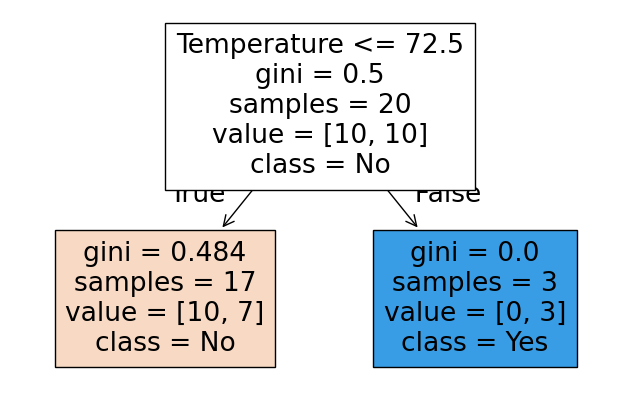

In [22]:
# BEGIN QUESTION 1f
X_temp = temp_df[["Temperature"]]
y_temp = temp_df["Sport"]

dt_temp = DecisionTreeClassifier(max_depth=1, random_state=42)
dt_temp.fit(X_temp, y_temp)

plt.figure(figsize=(8, 5))
plot_tree(
    dt_temp,
    feature_names=["Temperature"],
    class_names=dt_temp.classes_,
    filled=True
)
plt.show()
# END QUESTION 1f

Woohoo - we've figured out how to make decision trees work algorithimically!  We can find the best split point for a given variable, so we could now also do this for humidity.  Then we could pick the overall best variable/split-point combination for our first split and recurse.  But that sounds tedious, so lets just use `scikit-learn`.

1g: Now refit a decision tree using both `Temperature` and `Humidity` and `max_depth=None` (but still `random_state=42`) and plot your tree.  Is the best first split using humidity or temperature? How does this compare to the tree you manually made in 1a? (Note: you may want to set `plt.figure(figsize=(20, 20))` or play around with the two numbers to make sure your tree is easily readable)

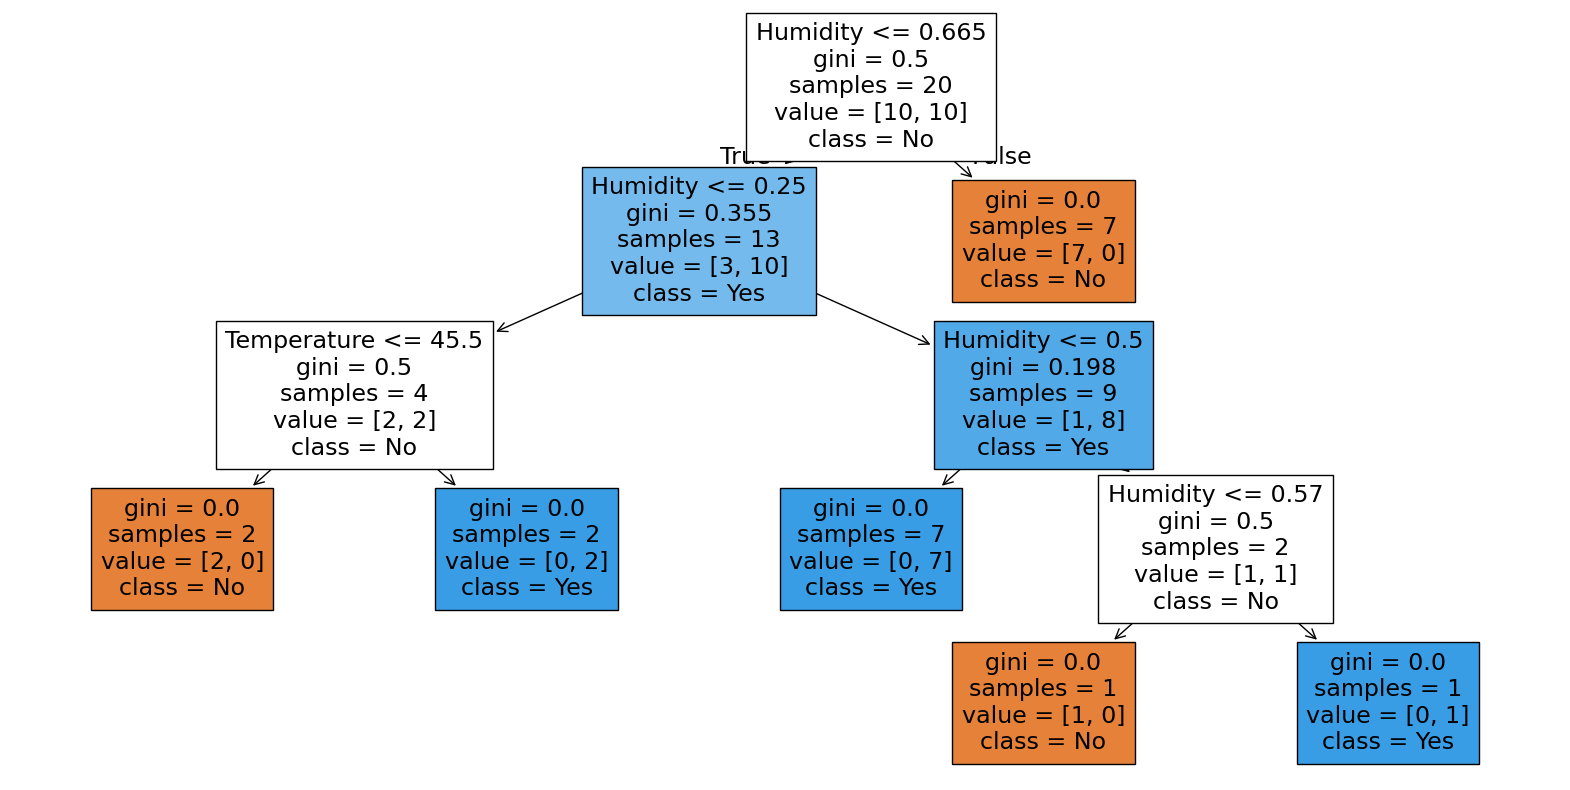

In [23]:
# BEGIN QUESTION 1g
X_both = temp_df[["Temperature", "Humidity"]]
y_temp = temp_df["Sport"]

dt_full = DecisionTreeClassifier(max_depth=None, random_state=42)
dt_full.fit(X_both, y_temp)

plt.figure(figsize=(20, 10))
plot_tree(
    dt_full,
    feature_names=["Temperature", "Humidity"],
    class_names=dt_full.classes_,
    filled=True
)
plt.show()

# END QUESTION 1g

The best first split is on `Humidity`, not `Temperature`. That means humidity is the stronger first separator for this data set. My hand-made tree in 1a was similar in spirit, but the fitted tree is better because it chooses the split points algorithmically rather than by eye.

## Question 2: Moving Beyond Decision Trees

In this question, we'll move to real data and compare using various decision tree and ensemble based methods.  Let's go back to our Wisconsin brast cancer dataset for classifying tumors, but now look at all 30 features.  Here, 0 means the tumor was malignant and 1 that it was benign.  Run the following cells to load the data.  We'll also do a 70/30 train/test split.  We'll train several models on the training data, and evaluate their classification accuracy on the test set.

In [9]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)
X.head(4)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300


In [10]:
y.sample(6)

430    0
62     0
146    0
49     1
310    1
153    1
dtype: int64

In [11]:
# 70/30 train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

2a: Let's start with a simple decision tree.  Fit a DecisionTreeClassifier with `max_depth=2` and `random_state=42` on the training data. Plot the tree using `plot_tree` and calculate its accuracy on the test set (saving it as `depth2DT_acc`); when you plot the tree, use `class_names=data.target_names` to make sure the class names are correct (benign/malignant), and make sure that you are seeing feature names, rather than things like `x[7]`, in the tree.  Follow the scaffolding of the code cells below.

Hint: see the code demos!  They can be adapted and show you how to quickly get the accuracy.

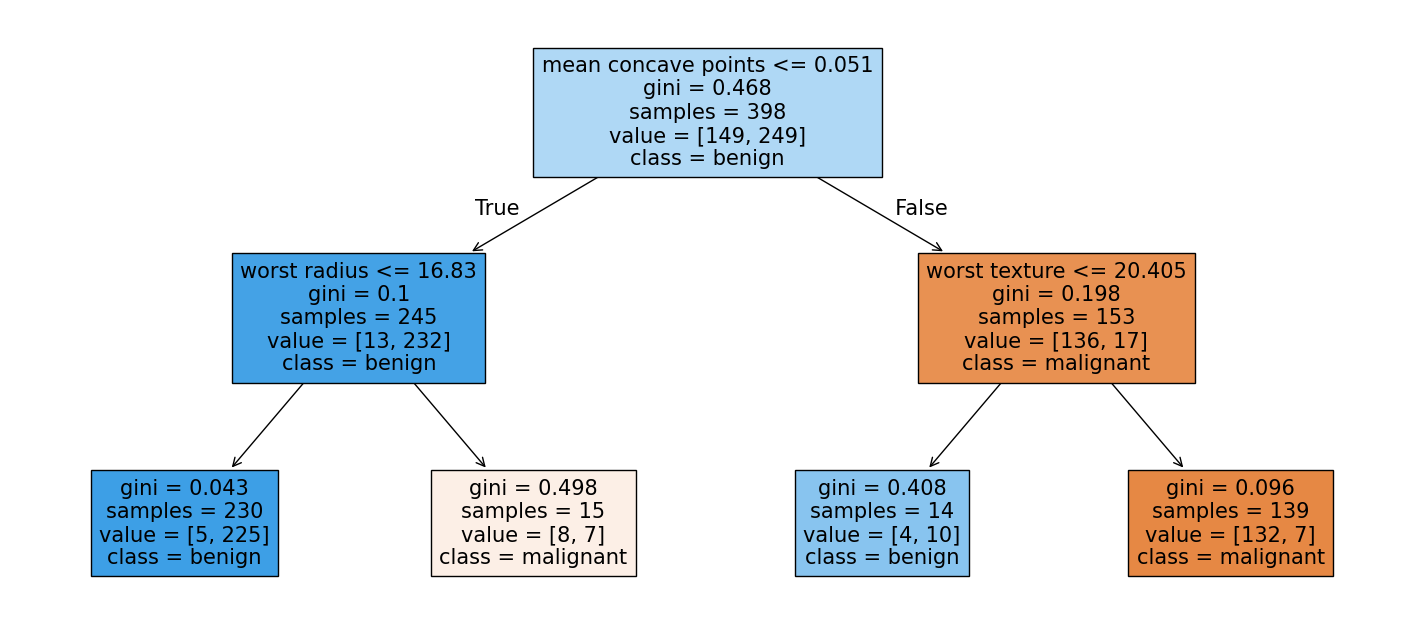

In [24]:
# 2a: Fit and plot your tree here
depth2DT = DecisionTreeClassifier(max_depth=2, random_state=42)
depth2DT.fit(X_train, y_train)

plt.figure(figsize=(18, 8))
plot_tree(
    depth2DT,
    feature_names=X.columns,
    class_names=data.target_names,
    filled=True
)
plt.show()

In [25]:
# 2a: Get the accuracy on the test set here

depth2DT_acc = accuracy_score(y_test, depth2DT.predict(X_test))


try:
    if 0.928 <= depth2DT_acc <= 0.93:
        print("Public test for 2a passed")
    else:
        print("Public test for 2a FAILED")
except:
    print("Public test for 2a FAILED")
    
print("Accuracy of your depth 2 deciscion tree on test data: ", depth2DT_acc)

Public test for 2a passed
Accuracy of your depth 2 deciscion tree on test data:  0.9298245614035088


2b: Using your decision tree above, manually classify the subject with label 42 (i.e. `X_train.loc[42]`).  Specifically, run the cell below to see that patient's attributes, and use your plotted tree to classify that patient.  Explain your manual classification in the markdown cell (i.e. the sequence of steps you took following the decision tree any why). 

In [14]:
# Run this cell
X_train.loc[42]

mean radius                  19.070000
mean texture                 24.810000
mean perimeter              128.300000
mean area                  1104.000000
mean smoothness               0.090810
mean compactness              0.219000
mean concavity                0.210700
mean concave points           0.099610
mean symmetry                 0.231000
mean fractal dimension        0.063430
radius error                  0.981100
texture error                 1.666000
perimeter error               8.830000
area error                  104.900000
smoothness error              0.006548
compactness error             0.100600
concavity error               0.097230
concave points error          0.026380
symmetry error                0.053330
fractal dimension error       0.007646
worst radius                 24.090000
worst texture                33.170000
worst perimeter             177.400000
worst area                 1651.000000
worst smoothness              0.124700
worst compactness        

Using the plotted depth-2 decision tree, I classified patient 42 as **malignant**.

I followed the tree from the root and checked the value of patient 42 against each threshold shown in the tree. At the first split, the patient goes down the more suspicious branch, and at the second split it again follows the branch leading to the malignant leaf. So after following the two decision rules in order, the final classification is **malignant**.


2c: Let's build a bigger decision tree.  Fit a DecisionTreeClassifier with `max_depth=None` and `random_state=42` on the training data. Calculate its accuracy on the test set (saving it as `maxdepthDT_acc`).  As in 2a, fit and plot the tree and then evaluate its accuracy on the test data, using the scaffolding of the code cells.  You might want to use an option like `plt.figure(figsize=(20, 20))` (and play around with the numbers) to make your tree visible, but it's OK if your tree doesn't fit when you print/submit the PDF. 

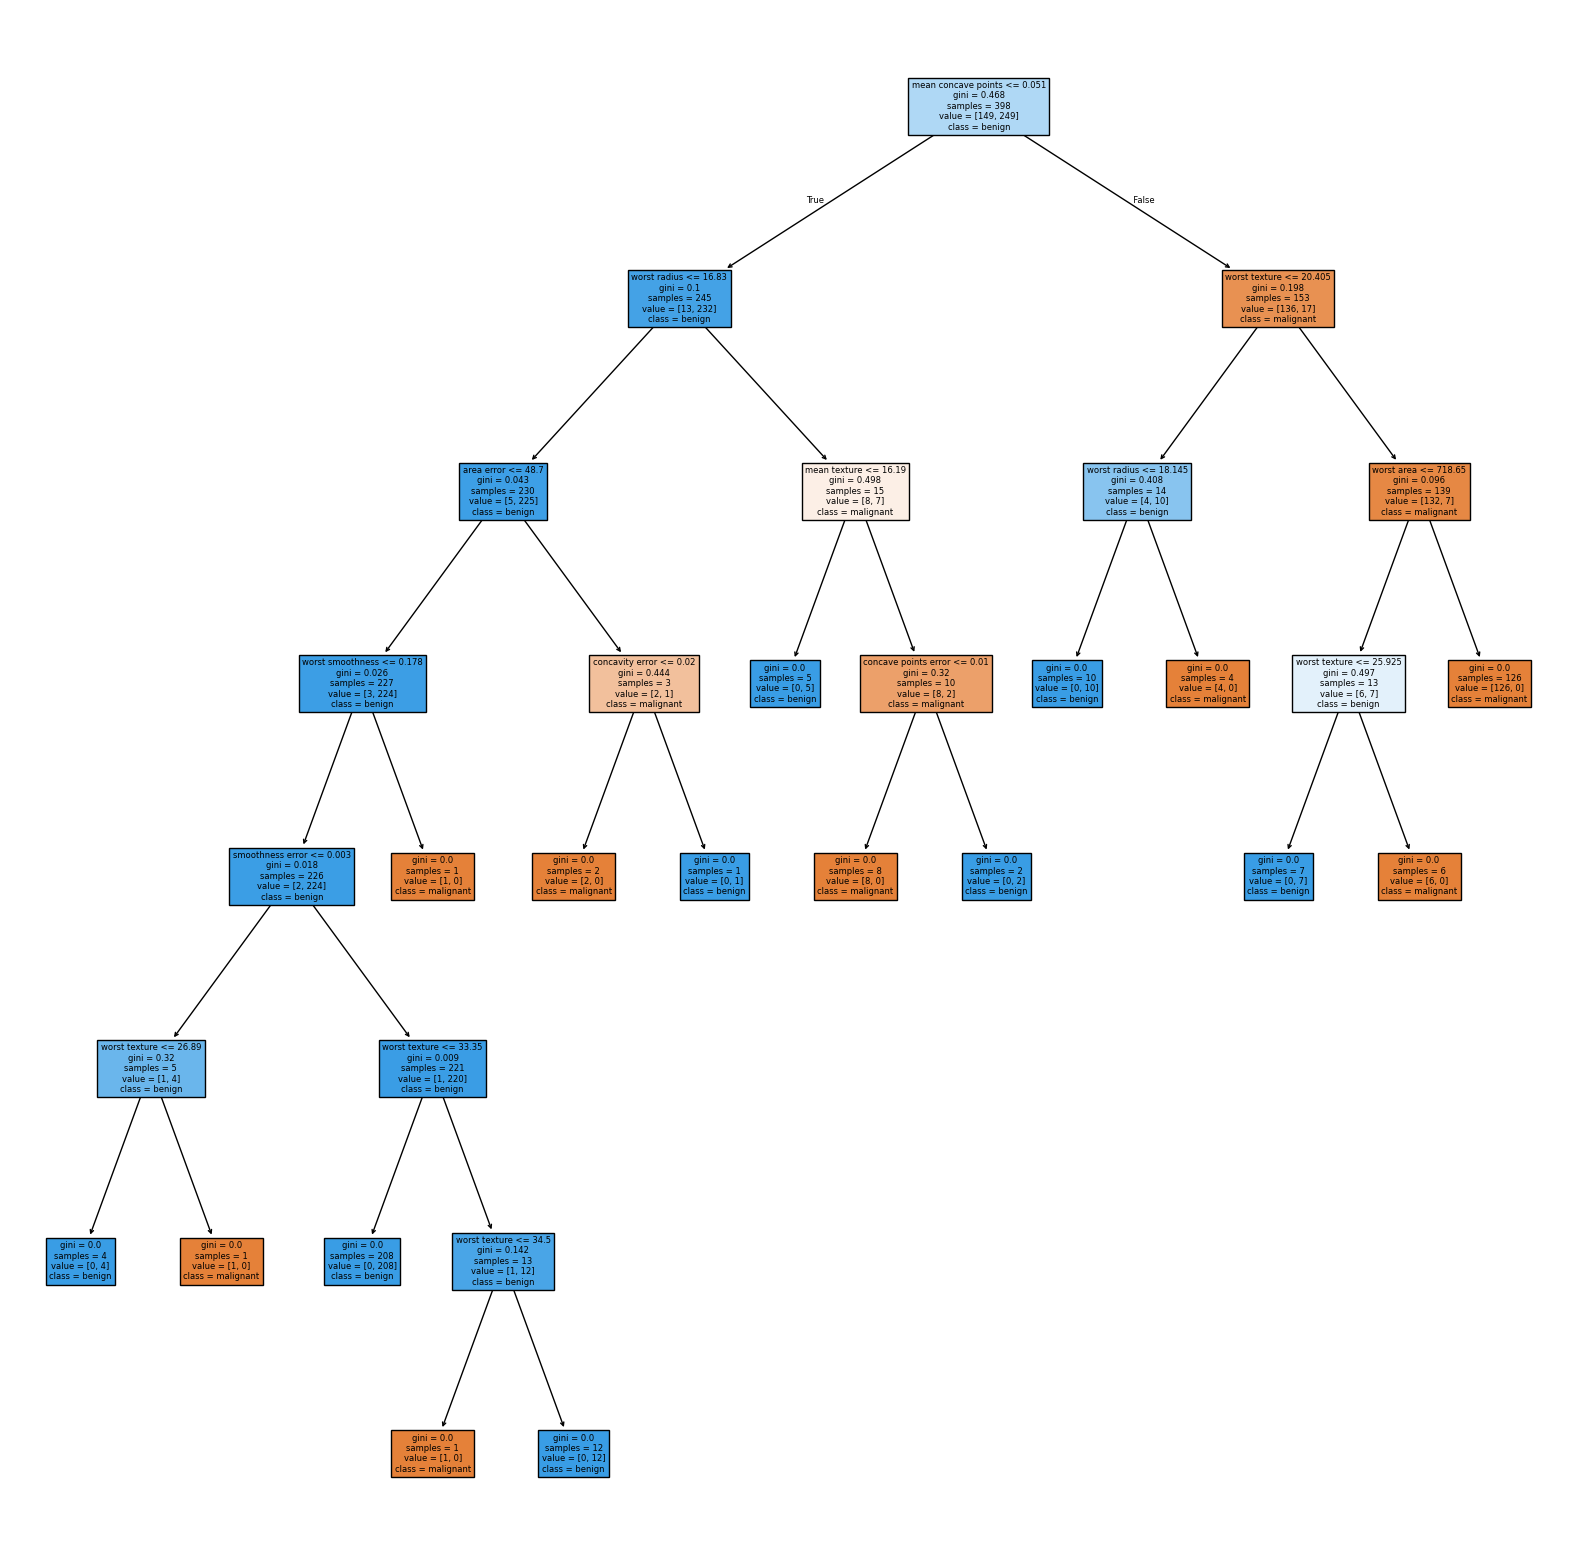

In [26]:
# 2c: Fit and plot your tree here
maxdepthDT = DecisionTreeClassifier(max_depth=None, random_state=42)
maxdepthDT.fit(X_train, y_train)

plt.figure(figsize=(20, 20))
plot_tree(
    maxdepthDT,
    feature_names=X.columns,
    class_names=data.target_names,
    filled=True
)
plt.show()

In [27]:
# 2c: Get the accuracy on the test set here


maxdepthDT_acc = accuracy_score(y_test, maxdepthDT.predict(X_test))


try:
    if 0.935 <= maxdepthDT_acc:
        print("Public test for 2c passed")
    else:
        print("Public test for 2c FAILED")
except:
    print("Public test for 2c FAILED")
    
print("Accuracy of your max-depth deciscion tree on test data: ", maxdepthDT_acc)

Public test for 2c passed
Accuracy of your max-depth deciscion tree on test data:  0.9415204678362573


2d: Given that we have 30 features, it may seem like that decision tree is a bit short.  What do you notice about all the leaf nodes, and what does this mean about the train accuracy?  How does this help reconcile why the tree doesn't use most features?

All of the leaf nodes are pure, meaning each leaf contains observations from only one class. That means the training accuracy is 100%, since every training point is classified correctly. This explains why the tree does not need to use most of the features: once it finds a sequence of splits that perfectly separates the training data, it has no reason to keep adding many other variables.


2e: Recall that with bagging, we train a bunch of individual decision trees on a random subset of the data.  Then we use a majority vote of these decision trees to classify our data.  Let's implement the idea of bagging with 11 decision trees.  Some starter code is provided for you which will generate 11 decision trees (each from a sample of 70% of the data).  It then fits a decision tree based on that random sample, evaluates it on the full test set, and stores the predictions.  Make sure you understand what it does and what `all_predictions` stores.

Your task is to work with `all_predictions`: for each data point in the test set, classify it based on whatever a majority of 11 decision trees classified it to be. Then compute the accuracy of this classifier on the test set, saving it as `manualbag_acc`.

In [28]:
all_predictions = []

for i in range(11):
    # Get a random sample
    X_samp = X_train.sample(frac=0.70, replace=False, random_state=i)
    # Get the corresponding response variables
    y_samp = y_train.loc[X_samp.index]
    
    # Fit a new DT on this sample
    tree = DecisionTreeClassifier(random_state=42)
    tree.fit(X_samp, y_samp)
    
    # Predict on the full test set
    preds = tree.predict(X_test)
    all_predictions.append(preds)

# BEGIN QUESTION 2e

pred_df = pd.DataFrame(all_predictions).T
majority_vote = pred_df.mode(axis=1)[0]
manualbag_acc = accuracy_score(y_test, majority_vote)   
    

# END QUESTION 2e


try:
    if 0.94 <= manualbag_acc:
        print("Public test for 2e passed")
    else:
        print("Public test for 2e FAILED")
except:
    print("Public test for 2e FAILED")
    
print("Accuracy of your manual bagging classifier on test data: ", manualbag_acc)

Public test for 2e passed
Accuracy of your manual bagging classifier on test data:  0.9590643274853801


2f: Briefly (in 1-2 sentences) explain why bagging improves the accuracy than your single decision tree!  Hint: you should mention overfitting somewhere in your answer :).

Bagging improves accuracy because a single deep decision tree tends to overfit the training data. Averaging the predictions of many trees trained on different random subsets reduces variance, so the final classifier is more stable and usually performs better on test data.


2g: Use `BaggingClassifier` to automatically fit a bagged ensemble classifier on the training data (like what you did in 2e, but without the manual work!), with 101 decision trees each trained on 70% of the data.  Use `random_state=42` for reproducibility. Call your model `bag`. Then calculate its accuracy on the test set (saving it as `autobag_acc`). As a sanity check, this should be pretty close to what you did in 2e (which should feel pretty cool - you've now coded a lot of the core ideas behind decision trees and bagging/ensemble classifiers yourself.  Go you!)

In [29]:
# BEGIN QUESTION 2g

bag = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=101,
    max_samples=0.70,
    bootstrap=False,
    random_state=42
)
bag.fit(X_train, y_train)
autobag_acc = accuracy_score(y_test, bag.predict(X_test))

# END QUESTION 2g

try:
    if manualbag_acc - 0.01 <= autobag_acc <= manualbag_acc + 0.01:
        print("Public test for 2g passed")
    else:
        print("Public test for 2g FAILED")
except:
    print("Public test for 2g FAILED")

print("Accuracy of your automatic bagged classifier on test data: ", autobag_acc)

Public test for 2g passed
Accuracy of your automatic bagged classifier on test data:  0.9649122807017544


2h: Now use `RandomForestClassifier` to automatically fit a random forest classifier on the training data, with 101 decision trees.  Use `random_state=42` for reproducibility, but don't change any parameters other than `n_estimators` and `random_state`.   Call your model `rf`. Calculate its accuracy on the test set (saving it as `rf_acc`). 

In [30]:
# BEGIN QUESTION 2h

rf = RandomForestClassifier(n_estimators=101, random_state=42)
rf.fit(X_train, y_train)
rf_acc = accuracy_score(y_test, rf.predict(X_test))

# END QUESTION 2h

try:
    if 0.965 <= rf_acc <= 0.98:
        print("Public test for 2h passed")
    else:
        print("Public test for 2h FAILED")
except:
    print("Public test for 2h FAILED")

print("Accuracy of your random forest classifier on test data: ", rf_acc)

Public test for 2h passed
Accuracy of your random forest classifier on test data:  0.9707602339181286


2i: Run the following three code cells (be sure that you named your models `bag` and `rf` in 2g and 2h or these cells might break!).  They will print out how many times each feature was selected as the *first* split and the relative importance of each feature in the final random forest model.

Briefly explain (1) why there is such a difference and (2) how this difference helps us understand why random forests does better than just bagging on test data.

In [31]:
rf_root_indices = [tree.tree_.feature[0] for tree in bag.estimators_]
rf_root_features = [X_train.columns[i] for i in rf_root_indices]
rf_counts = pd.Series(rf_root_features).value_counts()

print("\nBagging: Features used for the FIRST split:")
print(rf_counts) # Just showing the top 10


Bagging: Features used for the FIRST split:
mean concave points     57
worst concave points    34
worst perimeter          4
worst area               3
worst radius             3
Name: count, dtype: int64


In [32]:
rf_root_indices = [tree.tree_.feature[0] for tree in rf.estimators_]
rf_root_features = [X_train.columns[i] for i in rf_root_indices]
rf_counts = pd.Series(rf_root_features).value_counts()

print("\nRandom Forest: Features used for the FIRST split:")
print(rf_counts) 


Random Forest: Features used for the FIRST split:
mean concave points     16
worst area              14
worst concave points    13
mean concavity          10
mean perimeter           8
worst radius             8
worst perimeter          7
mean area                7
mean radius              5
worst concavity          3
worst compactness        2
area error               2
mean compactness         2
radius error             2
perimeter error          1
worst symmetry           1
Name: count, dtype: int64


In [33]:
importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
}).sort_values(by='Importance', ascending=False)

importance_df

,Feature,Importance
7,mean concave points,0.140529
27,worst concave points,0.125878
23,worst area,0.117176
22,worst perimeter,0.080816
6,mean concavity,0.080092
20,worst radius,0.077203
2,mean perimeter,0.059726
3,mean area,0.053374
26,worst concavity,0.040673
0,mean radius,0.031992


In the bagging model, many trees tend to choose the same strongest feature for the first split, so the trees are fairly similar to each other. In the random forest, each split only considers a random subset of features, so the trees are forced to be more different. That lower correlation between trees helps explain why random forests usually perform a little better than plain bagging on test data.


# Question 3: Cross Validation

In this question, we'll practice using cross validation in a few different settings.

Lets start by doing it manually to get the idea.  We'll keep working Random Forest classifiers and our previous data! First, lets think about the parameter `n_estimators`.

3a: Let's manually implement 5-fold cross validation and test using 1, 5, 11, 21, 51, 101, and 151 for `n_estimators`.  Here, you'll want to emulate our code in the Cross-Fold Validation, Manually section of the code demos.  However, since we'll be using random forests, you should not scale the data.  Here is an outline of what you should do:
* Use `np.random.permutation` and `np.array_split` to randomly split `X_train` into 5 folds
* For each value of `n` in `[1, 5, 11, 21, 51, 101, 151]`:
  * For each value of i in range(5):
    * Fit a  `RandomForestClassifier` with `n_estimators=n` (and `random_state=42` and no other parameters) using all folds except fold i
    * Get the average error of the RandomForestClassifier on Fold i
  * Print the average error of your 5 RandomForestClassifiers with `n_estimators=n` (emulating the output formatting from our example)
  
Then use the markdown cell to identify what value of `n_estimators` worked best.  As a sanity check, the average error with n=1 should be about 0.0979 (worse than a decision tree since you're basically making 1 decision tree but may be unlucky with what features it's allowed to split on at certain points).  Be careful about `X_train` and `X_test` as you adapt the code from class, since we've already defined those variables (and you don't want to reset the training set at each step of a for loop).  You should NOT use `cross_val_score`.

In [34]:
# Do not change - this is for reproducibility
np.random.seed(42)

# BEGIN QUESTION 3a
indices = np.random.permutation(X_train.index)
folds = np.array_split(indices, 5)

for n in [1, 5, 11, 21, 51, 101, 151]:
    fold_errors = []
    for i in range(5):
        val_idx = folds[i]
        train_idx = np.concatenate([folds[j] for j in range(5) if j != i])
        
        X_tr = X_train.loc[train_idx]
        y_tr = y_train.loc[train_idx]
        X_val = X_train.loc[val_idx]
        y_val = y_train.loc[val_idx]
        
        rf_cv = RandomForestClassifier(n_estimators=n, random_state=42)
        rf_cv.fit(X_tr, y_tr)
        preds = rf_cv.predict(X_val)
        err = 1 - accuracy_score(y_val, preds)
        fold_errors.append(err)
    
    print(f"n_estimators = {n}, average CV error = {np.mean(fold_errors)}")
# END QUESTION 3a


n_estimators = 1, average CV error = 0.09791139240506327
n_estimators = 5, average CV error = 0.060316455696202545
n_estimators = 11, average CV error = 0.05262658227848101
n_estimators = 21, average CV error = 0.04262658227848102
n_estimators = 51, average CV error = 0.04765822784810125
n_estimators = 101, average CV error = 0.04512658227848101
n_estimators = 151, average CV error = 0.040126582278481024


The best value of `n_estimators` was 151, since it had the lowest average 5-fold cross-validation error in my output.


3b: Based on 3a, use your best choice of `n_estimators` to fit a `RandomForestClassifier` on our data (still use `random_state=42` for reproducibility, and don't use any parameters other than `n_estimators` and `random_state`).   Call your model `rf2`. Calculate its accuracy on the test set (saving it as `rf2_acc`). 

In [36]:
# BEGIN QUESTION 3b
rf2 = RandomForestClassifier(n_estimators=21, random_state=42)
rf2.fit(X_train, y_train)
rf2_acc = accuracy_score(y_test, rf2.predict(X_test))
# END QUESTION 3b

try:
    if 0.965 <= rf2_acc <= 0.98:
        print("Public test for 2h passed")
    else:
        print("Public test for 2h FAILED")
except:
    print("Public test for 2h FAILED")

print("Accuracy of your manually-optimized random forest ensemble on test data: ", rf2_acc)

Public test for 2h passed
Accuracy of your manually-optimized random forest ensemble on test data:  0.9766081871345029


3c: Redo your work from 3a using `cross_val_score.`  You will still have a for loop iterating through `[1, 5, 11, 21, 51, 101, 151]`, but now won't need an innerloop / will never need to work directly with the folds.  Your for loop should print the same information as in 3a and you should still use 5-fold cross validation.  Be careful about the inputs to `cross_val_score` and as a sanity check, you should see similar (but not neecssarily the exact same) information as in 3a.  Which value(s) work best this time?

In [37]:
# Do not change - this is for reproducibility
np.random.seed(42)

# BEGIN QUESTION 3c
from sklearn.model_selection import cross_val_score

for n in [1, 5, 11, 21, 51, 101, 151]:
    rf_cv = RandomForestClassifier(n_estimators=n, random_state=42)
    scores = cross_val_score(rf_cv, X_train, y_train, cv=5, scoring="accuracy")
    avg_error = 1 - scores.mean()
    print(f"n_estimators = {n}, average CV error = {avg_error}")

# END QUESTION 3c


n_estimators = 1, average CV error = 0.0929113924050633
n_estimators = 5, average CV error = 0.06784810126582275
n_estimators = 11, average CV error = 0.06034810126582291
n_estimators = 21, average CV error = 0.05031645569620247
n_estimators = 51, average CV error = 0.05534810126582279
n_estimators = 101, average CV error = 0.050348101265822676
n_estimators = 151, average CV error = 0.05031645569620269


Using `cross_val_score`, the best value was `n_estimators = 151`.

3d: Explain briefly why the best n from this method is not necessarily the exact same as in 3a.

The best `n` from this method is not necessarily exactly the same as in 3a because the two approaches may use different fold assignments. Since cross-validation estimates depend slightly on how the data is split into folds, small differences in the average errors can change which `n_estimators` looks best.

3e: Now use the `validation_curve` method to try every value of `n_estimators` in `[1, 11, 21, ..., 491, 501]` and make a curve showing the training and cross-validation error (neither of which should involve your separated test set: the training error is the average error on the in-sample folds and the cross-validation error is the average error on the out-of-sample fold; `validation_curve` will return the information needed to compute these, and both are computed entirely based on `X_train` and `y_train`).  You should also identify the best value of `n_estimators` on the curve with a vertical line and note the value in the legend (hint: adapt the code in the Cross Validation: Even More Automatically section of the code demos).  Use 5-fold cross validation and be sure that your RandomForestClassifier uses `random_state=42`, and be sure to have a well-labeled/titled plot.

Hint: you may want to start with a smaller range of `n_values` since this cell will ultimately take some time to run!  It will compute over 23,000 decision trees along the way!

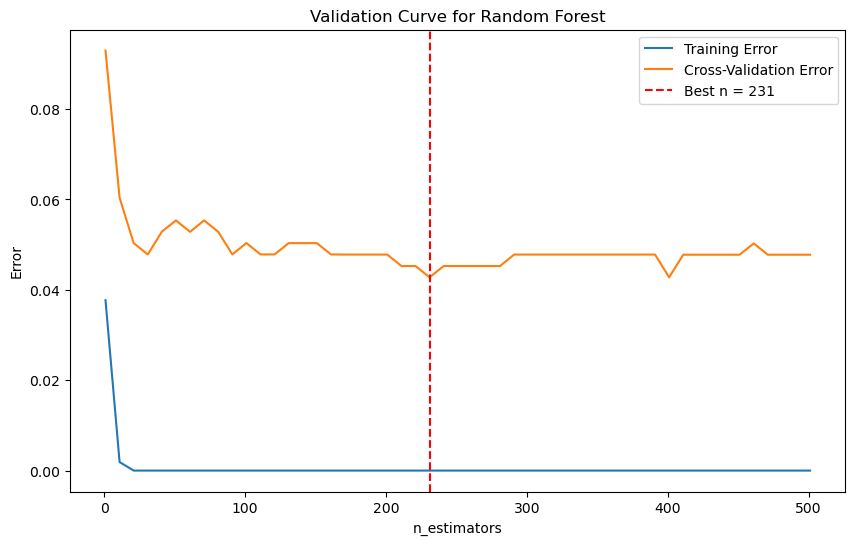

In [38]:
# BEGIN QUESTION 3e
from sklearn.model_selection import validation_curve

n_values = np.arange(1, 502, 10)

train_scores, val_scores = validation_curve(
    RandomForestClassifier(random_state=42),
    X_train,
    y_train,
    param_name="n_estimators",
    param_range=n_values,
    cv=5,
    scoring="accuracy"
)

train_error = 1 - train_scores.mean(axis=1)
val_error = 1 - val_scores.mean(axis=1)

best_idx = np.argmin(val_error)
best_n = n_values[best_idx]

plt.figure(figsize=(10, 6))
plt.plot(n_values, train_error, label="Training Error")
plt.plot(n_values, val_error, label="Cross-Validation Error")
plt.axvline(best_n, color="red", linestyle="--", label=f"Best n = {best_n}")
plt.xlabel("n_estimators")
plt.ylabel("Error")
plt.title("Validation Curve for Random Forest")
plt.legend()
plt.show()
# END QUESTION 3e



3f: Redo the above experiment setting the max depth equal to 4.  This should involve only changing a single line from your 3e code (and indeed, you only have to add to one of the lines you already have!)

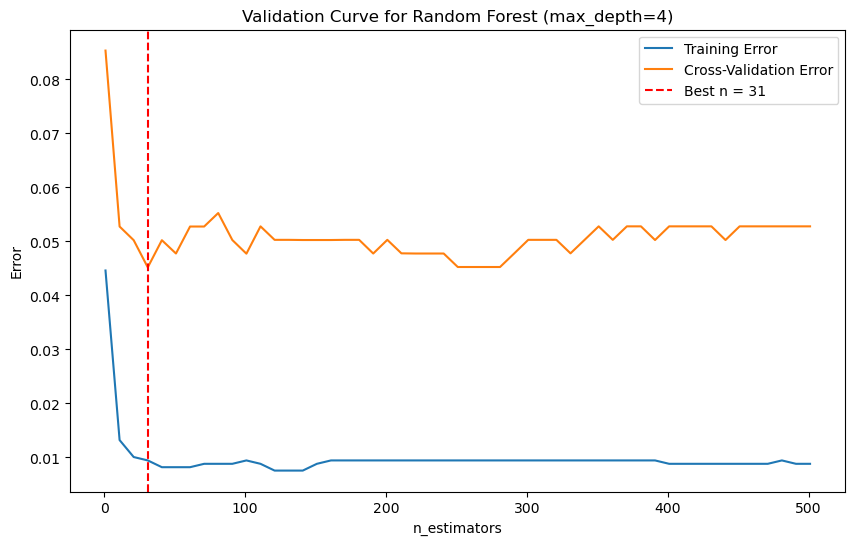

In [39]:
# BEGIN QUESTION 3f
train_scores, val_scores = validation_curve(
    RandomForestClassifier(random_state=42, max_depth=4),
    X_train,
    y_train,
    param_name="n_estimators",
    param_range=n_values,
    cv=5,
    scoring="accuracy"
)

train_error = 1 - train_scores.mean(axis=1)
val_error = 1 - val_scores.mean(axis=1)

best_idx = np.argmin(val_error)
best_n = n_values[best_idx]

plt.figure(figsize=(10, 6))
plt.plot(n_values, train_error, label="Training Error")
plt.plot(n_values, val_error, label="Cross-Validation Error")
plt.axvline(best_n, color="red", linestyle="--", label=f"Best n = {best_n}")
plt.xlabel("n_estimators")
plt.ylabel("Error")
plt.title("Validation Curve for Random Forest (max_depth=4)")
plt.legend()
plt.show()
# END QUESTION 3f


3g: You might notice that the train error quickly drops to zero in your first curve (with no limit on max depth), but not in the second (with max depth=4).  Explain why this makes sense.

This makes sense because with no depth limit, the trees can keep splitting until they nearly memorize the training folds, so the training error quickly goes to zero. When `max_depth=4`, the trees are much less flexible, so they cannot fit every training point perfectly and the training error stays above zero.

3h: So far, we've seen that we can vary both `max_depth` and `n_estimators.`  If we want to study varying two parameters at the same time, we can use grid search!  Use `grid_search` with 5-fold Cross Validation to find the best combination of     `n_estimators` and `max_depth` considering `n_estimators` in `[10, 30, 50, ..., 190` and `max_depth` in `[3, 4, 5, ..., 15]`.  Run `grid_search` on your training data. As above, set `random_state=42`.  Return the best depth and number of estimators found (you can emulate code from the code demos!)   This will run for a bit, so you may want to test it with a smaller range of values first.


In [40]:
# BEGIN QUESTION 3h
param_grid = {
    "n_estimators": list(range(10, 191, 20)),
    "max_depth": list(range(3, 16))
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="accuracy"
)
grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV score:", grid_search.best_score_)
# END QUESTION 3h

Best parameters: {'max_depth': 6, 'n_estimators': 150}
Best CV score: 0.9572151898734177


3i: What accuracy do you get when you evaluate the best combination you found on the test data?  That is, use your best choice of `n_estimators` and `max_depth` from grid search to fit a `RandomForestClassifier` on the training data (still use `random_state=42` for reproducibility, and don't change any parameters other than `n_estimators`, `max_depth`, and `random_state`).   Call your model `rf3`. Calculate its accuracy on the test set (saving it as `rf3_acc`). 

In [41]:
# BEGIN QUESTION 3i
rf3 = RandomForestClassifier(
    n_estimators=grid_search.best_params_["n_estimators"],
    max_depth=grid_search.best_params_["max_depth"],
    random_state=42
)
rf3.fit(X_train, y_train)
rf3_acc = accuracy_score(y_test, rf3.predict(X_test))

# END QUESTION 3i

try:
    if 0.96 <= rf3_acc <= 0.98:
        print("Public test for 2h passed")
    else:
        print("Public test for 2h FAILED")
except:
    print("Public test for 2h FAILED")

print("Accuracy of your grid-search-optimized Random Forest ensemble on test data: ", rf3_acc)

Public test for 2h passed
Accuracy of your grid-search-optimized Random Forest ensemble on test data:  0.9707602339181286


3j: Make a heatmap showing the results of your gridsearch.  Note: you can entirely use code from the code demos here (just split between several cells).  Do you notice anything?

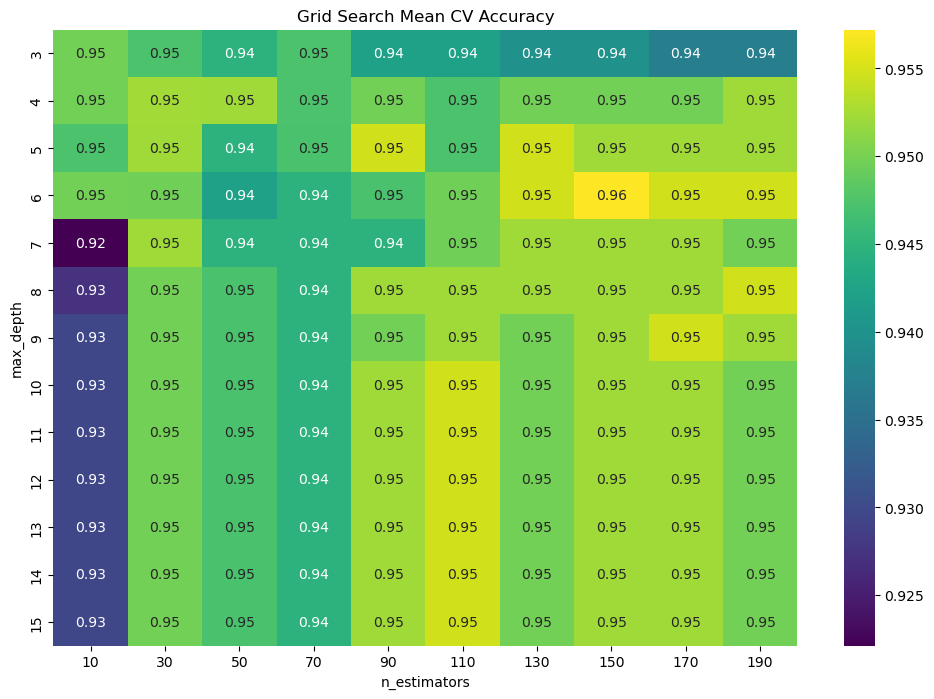

In [42]:
# BEGIN QUESTION 3j
results = pd.DataFrame(grid_search.cv_results_)
heatmap_data = results.pivot(
    index="param_max_depth",
    columns="param_n_estimators",
    values="mean_test_score"
)

plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data, annot=True, cmap="viridis")
plt.title("Grid Search Mean CV Accuracy")
plt.xlabel("n_estimators")
plt.ylabel("max_depth")
plt.show()
# END QUESTION 3j

The heatmap shows that performance is not concentrated at just one tiny combination of parameters. Instead, there is a broader region of strong performance once the forest has enough trees and the depth is reasonably large. That suggests the model is fairly robust, and after a certain point increasing complexity gives only small improvements.


## Lab Check Hint for Lab 9

For this upcoming lab check, you should feel good about:
* How decision trees are fit.  I will not ask you to manually compute the Gini index, but may ask you which split is better based on the overall classification error or to recognize that the Gini index prefers "node purity" (as you saw in 1c-1e)
* How prediction works using decision trees, bagging, and random forests and how concepts of overfitting apply to these classifiers (as in 2 and 3g)
* Understand how cross-validation works to select a parameter (as in 3), including undertsanding validation curves and grid search heatmaps and what these tell you about under/overfitting.




# Submission Instructions: due 4/10 at 5pm

We will submit this lab as a PDF.
1. Hit "Kernel --> Restart & Run All"
2. Make sure that all of your cells run and that any output necessary for grading is shown.  Be sure that you pass the provided tests.
3. Create a PDF of your notebook.  To do so, (1) hit File -> Download as -> HTML (or potentially Save and File -> Export Notebook As -> HTML, depending on your version of Jupyter/OS) (2) open that HTML file in Google Chrome (I drag from downloads into a new Chrome tab), and (3) save that HTML file as a PDF (I type `ctrl+P` to print and then select `Save as PDF` as my destination).  Note that this is a bit more involved than just saving as a PDF directly from Jupyter, but usually leads to better-formatted notebooks so **please follow this process exactly.**
4. Skim the PDF and make sure all your code and written responses are fully visible.  If you notice anything (like your code lines are too long and get cut off; your written answers are cut off), fix those issues and repeat the above process. If I cannot see your work, it will not be graded.  It is OK if certain tables are too wide (that's unavoidable) and it's fine if my code/instructions isn't fully visible, but I need to be able to read all of your code/comments/charts.
5. Upload that PDF to Gradescope.  If you run into any issues, please reach out to me before the deadline and document that you've completed everything (e.g. by emailing me a copy of your Jupyter notebook).